# ============================================================
# NETGUARD AI
# Notebook 10 - Model Comparison
# ============================================================

"""
Objective:
Compare all evaluated machine-learning approaches under
a common evaluation framework.

Scientific Question:
Which model provides the best overall balance between
DDoS detection performance, false-negative risk,
and computational cost?
"""

In [23]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
baseline_results = pd.read_csv(
    "baseline_model_results.csv"
)

advanced_results = pd.read_csv(
    "advanced_tree_model_results.csv"
)

svm_results = pd.read_csv(
    "svm_model_results.csv"
)

autoencoder_results = pd.read_csv(
    "autoencoder_classification_results.csv"
)

In [25]:
print("Baseline Results")
display(baseline_results)

print("\nAdvanced Tree Results")
display(advanced_results)

print("\nSVM Results")
display(svm_results)

print("\nAutoencoder Results")
display(autoencoder_results)

Baseline Results


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294,0.093739
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552,0.003906
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991,0.003906



Advanced Tree Results


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001,0.046870
1,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644,0.003906
2,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513,0.003906



SVM Results


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304



Autoencoder Results


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,1.218027,0.117174
1,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7.476504,0.031246
2,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,18.252770,0.039058


In [26]:
all_results = pd.concat(
    [
        baseline_results,
        advanced_results,
        svm_results,
        autoencoder_results
    ],
    ignore_index=True
)

all_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294,0.093739
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552,0.003906
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991,0.003906
3,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001,0.046870
4,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644,0.003906
5,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513,0.003906
6,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304
7,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,1.218027,0.117174
8,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7.476504,0.031246
9,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,18.252770,0.039058


In [27]:
all_results = all_results.drop_duplicates(
    subset=["Model"],
    keep="last"
).reset_index(drop=True)

display(all_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294,0.093739
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552,0.003906
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991,0.003906
3,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001,0.046870
4,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644,0.003906
5,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513,0.003906
6,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304
7,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,1.218027,0.117174
8,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7.476504,0.031246
9,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,18.252770,0.039058


In [28]:
f1_ranking = all_results.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(f1_ranking)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644,0.003906
1,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513,0.003906
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991,0.003906
3,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552,0.003906
4,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001,0.046870
5,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,18.252770,0.039058
6,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7.476504,0.031246
7,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553,0.070304
8,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,1.218027,0.117174
9,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294,0.093739


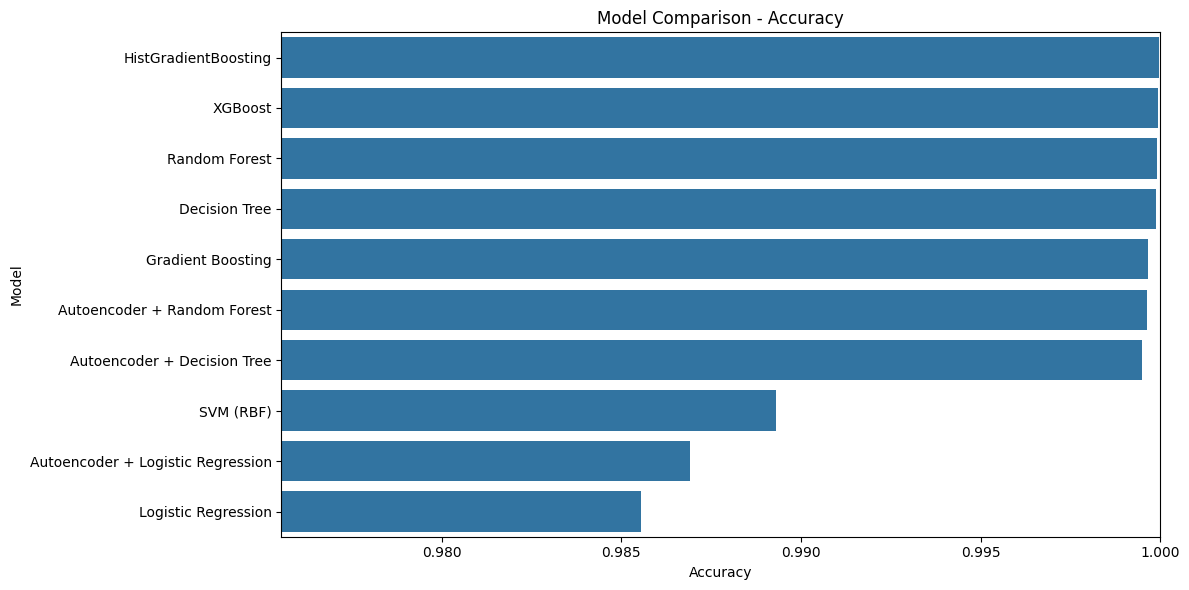

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results.sort_values(
        "Accuracy",
        ascending=False
    ),
    x="Accuracy",
    y="Model"
)

plt.title("Model Comparison - Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Model")

plt.xlim(
    max(0, all_results["Accuracy"].min() - 0.01),
    1.0
)

plt.tight_layout()
plt.show()

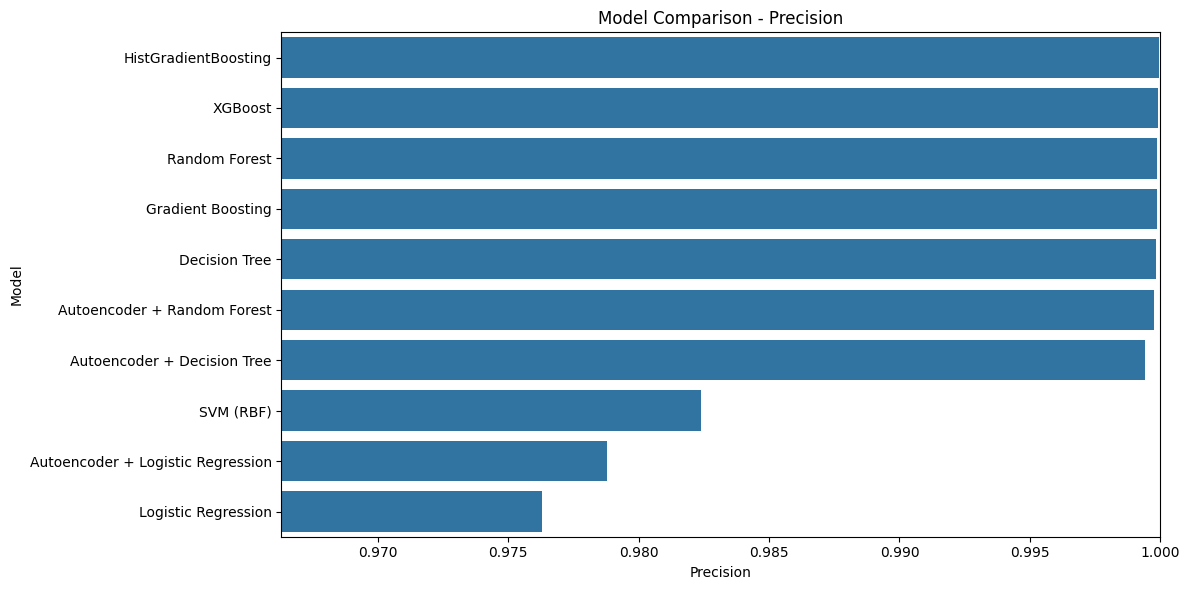

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results.sort_values(
        "Precision",
        ascending=False
    ),
    x="Precision",
    y="Model"
)

plt.title("Model Comparison - Precision")
plt.xlabel("Precision")
plt.ylabel("Model")

plt.xlim(
    max(0, all_results["Precision"].min() - 0.01),
    1.0
)

plt.tight_layout()
plt.show()

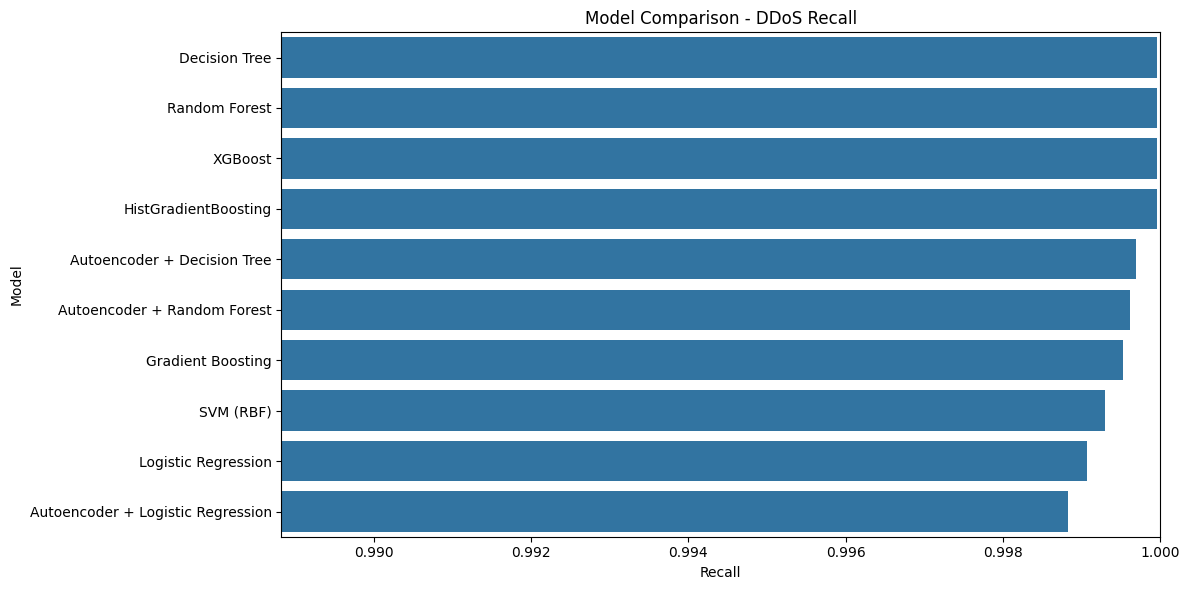

In [31]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results.sort_values(
        "Recall",
        ascending=False
    ),
    x="Recall",
    y="Model"
)

plt.title("Model Comparison - DDoS Recall")
plt.xlabel("Recall")
plt.ylabel("Model")

plt.xlim(
    max(0, all_results["Recall"].min() - 0.01),
    1.0
)

plt.tight_layout()
plt.show()

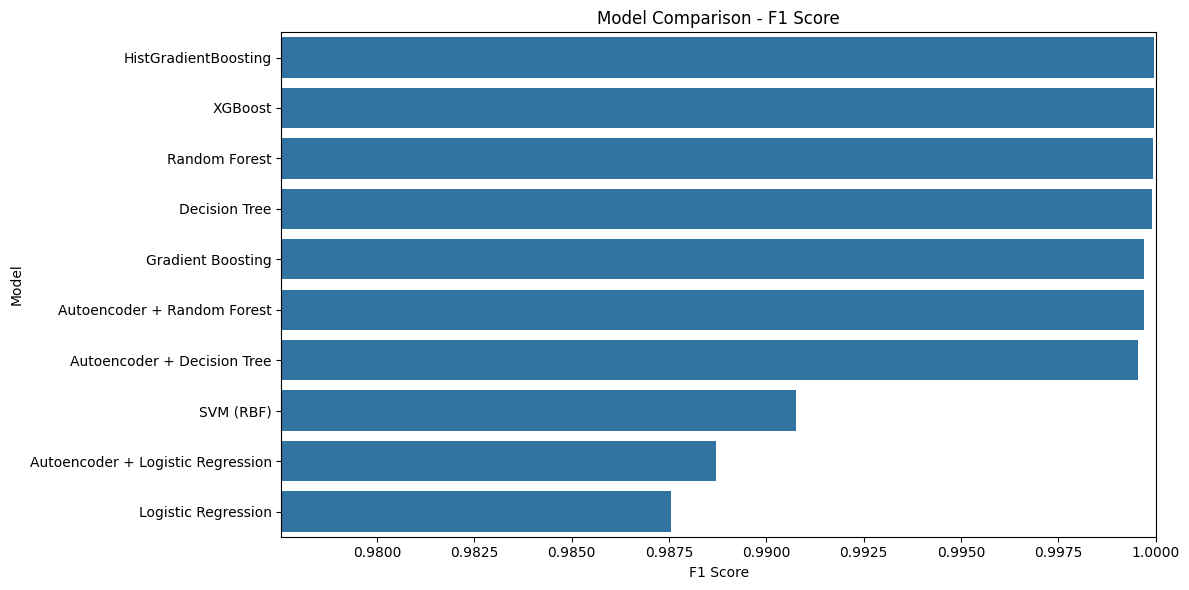

In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results.sort_values(
        "F1",
        ascending=False
    ),
    x="F1",
    y="Model"
)

plt.title("Model Comparison - F1 Score")
plt.xlabel("F1 Score")
plt.ylabel("Model")

plt.xlim(
    max(0, all_results["F1"].min() - 0.01),
    1.0
)

plt.tight_layout()
plt.show()

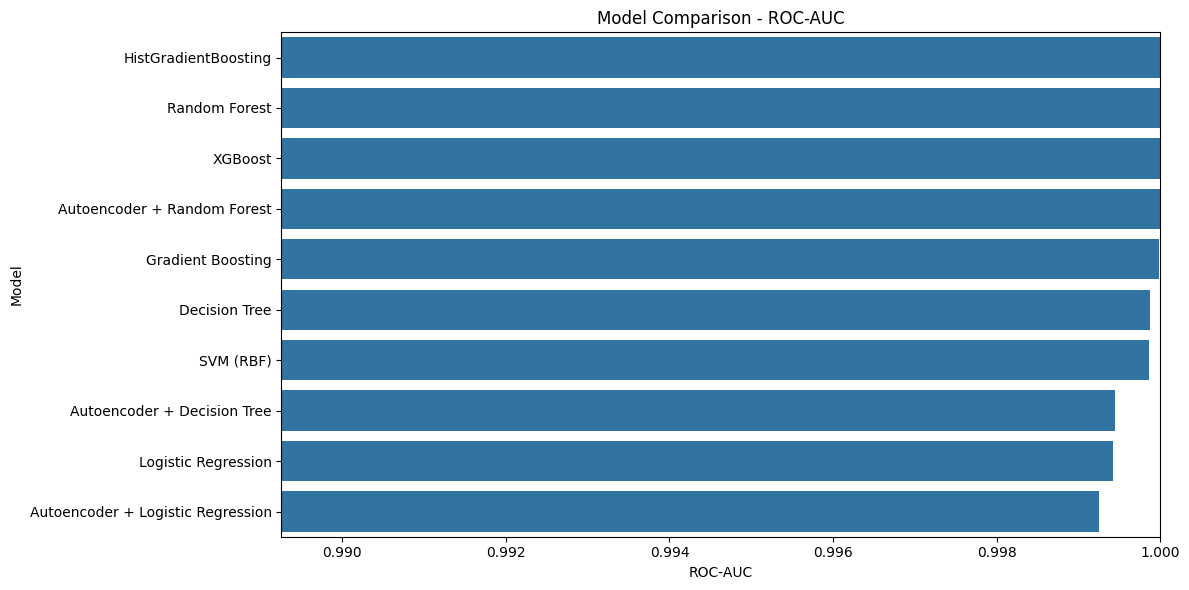

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results.sort_values(
        "ROC-AUC",
        ascending=False
    ),
    x="ROC-AUC",
    y="Model"
)

plt.title("Model Comparison - ROC-AUC")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")

plt.xlim(
    max(0, all_results["ROC-AUC"].min() - 0.01),
    1.0
)

plt.tight_layout()
plt.show()

In [34]:
comparison_table = all_results[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Training Time"
    ]
].sort_values(
    "F1",
    ascending=False
)

display(comparison_table)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time
4,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,2.335644
5,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,1.193513
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,9.005991
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,1.499552
3,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,92.513001
9,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,18.252770
8,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7.476504
6,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,18.907553
7,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,1.218027
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,1.786294


In [35]:
presentation_table = comparison_table.copy()

numeric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

presentation_table[numeric_columns] = (
    presentation_table[numeric_columns]
    .round(4)
)

presentation_table["Training Time"] = (
    presentation_table["Training Time"]
    .round(2)
)

display(presentation_table)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time
4,HistGradientBoosting,1.0000,1.0000,1.0000,1.0000,1.0000,2.34
5,XGBoost,0.9999,0.9999,1.0000,0.9999,1.0000,1.19
2,Random Forest,0.9999,0.9999,1.0000,0.9999,1.0000,9.01
1,Decision Tree,0.9999,0.9998,1.0000,0.9999,0.9999,1.50
3,Gradient Boosting,0.9997,0.9999,0.9995,0.9997,1.0000,92.51
9,Autoencoder + Random Forest,0.9996,0.9998,0.9996,0.9997,1.0000,18.25
8,Autoencoder + Decision Tree,0.9995,0.9994,0.9997,0.9996,0.9994,7.48
6,SVM (RBF),0.9893,0.9824,0.9993,0.9908,0.9999,18.91
7,Autoencoder + Logistic Regression,0.9869,0.9788,0.9988,0.9887,0.9993,1.22
0,Logistic Regression,0.9855,0.9763,0.9991,0.9875,0.9994,1.79


In [36]:
best_f1_model = all_results.loc[
    all_results["F1"].idxmax()
]

print("Best model based on F1-score:")
print(best_f1_model)

Best model based on F1-score:
Model            HistGradientBoosting
Accuracy                     0.999955
Precision                    0.999961
Recall                       0.999961
F1                           0.999961
ROC-AUC                           1.0
Training Time                2.335644
FNR (%)                      0.003906
Name: 4, dtype: object


In [37]:
best_recall_model = all_results.loc[
    all_results["Recall"].idxmax()
]

print("Best model based on DDoS Recall:")
print(best_recall_model)

Best model based on DDoS Recall:
Model            Decision Tree
Accuracy              0.999888
Precision             0.999844
Recall                0.999961
F1                    0.999902
ROC-AUC               0.999875
Training Time         1.499552
FNR (%)               0.003906
Name: 1, dtype: object


In [38]:
best_auc_model = all_results.loc[
    all_results["ROC-AUC"].idxmax()
]

print("Best model based on ROC-AUC:")
print(best_auc_model)

Best model based on ROC-AUC:
Model            HistGradientBoosting
Accuracy                     0.999955
Precision                    0.999961
Recall                       0.999961
F1                           0.999961
ROC-AUC                           1.0
Training Time                2.335644
FNR (%)                      0.003906
Name: 4, dtype: object


In [39]:
fastest_model = all_results.loc[
    all_results["Training Time"].idxmin()
]

print("Fastest model:")
print(fastest_model)

Fastest model:
Model             XGBoost
Accuracy         0.999933
Precision        0.999922
Recall           0.999961
F1               0.999941
ROC-AUC          0.999999
Training Time    1.193513
FNR (%)          0.003906
Name: 5, dtype: object


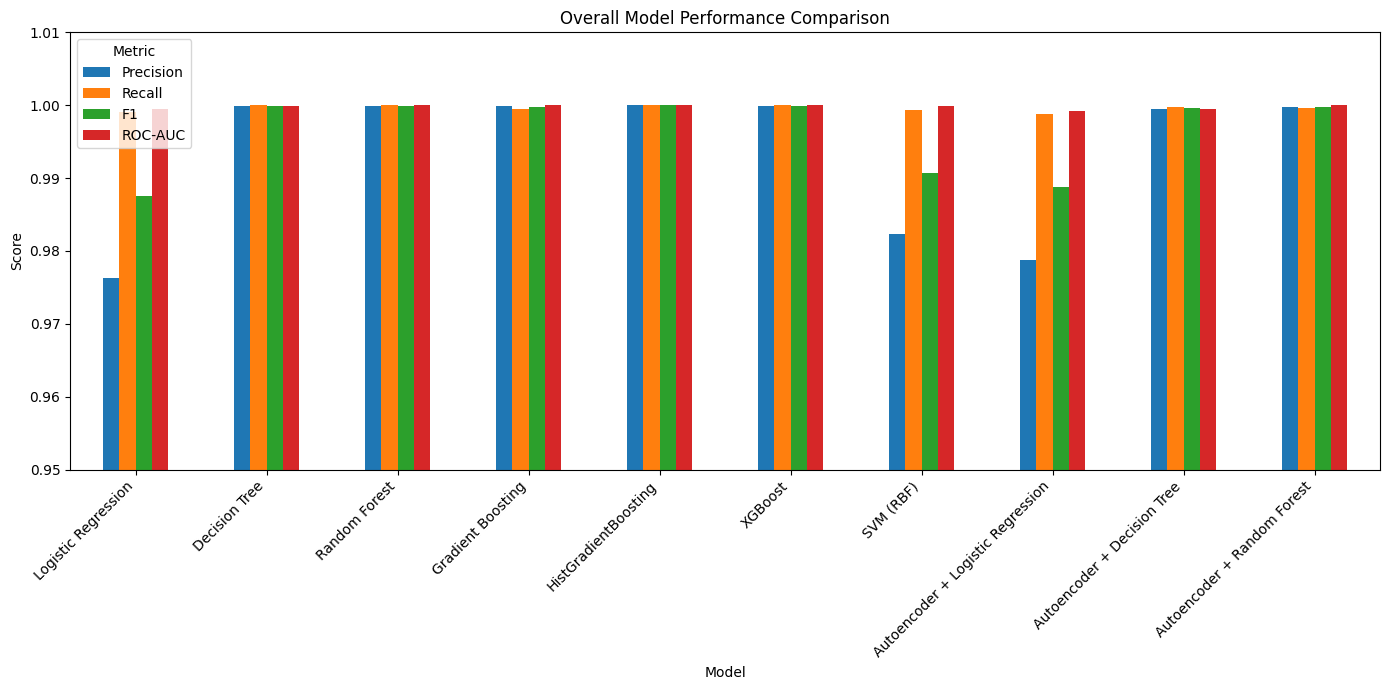

In [40]:
plot_data = all_results[
    [
        "Model",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
].set_index("Model")

plot_data.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Overall Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0.95, 1.01)

plt.legend(
    title="Metric"
)

plt.tight_layout()
plt.show()

In [41]:
ranking = all_results[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
].copy()

ranking["F1_Rank"] = (
    ranking["F1"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

ranking = ranking.sort_values(
    "F1_Rank"
)

display(ranking)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,F1_Rank
4,HistGradientBoosting,0.999955,0.999961,0.999961,0.999961,1.000000,1
5,XGBoost,0.999933,0.999922,0.999961,0.999941,0.999999,2
2,Random Forest,0.999910,0.999883,0.999961,0.999922,1.000000,3
1,Decision Tree,0.999888,0.999844,0.999961,0.999902,0.999875,4
3,Gradient Boosting,0.999664,0.999883,0.999531,0.999707,0.999990,5
9,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,6
8,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7
6,SVM (RBF),0.989309,0.982376,0.999297,0.990764,0.999867,8
7,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,9
0,Logistic Regression,0.985544,0.976298,0.999063,0.987549,0.999417,10


In [42]:
comparison_table.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Final model comparison saved.")

Final model comparison saved.


In [43]:
print("Best F1:")
print(best_f1_model["Model"])

print("\nBest Recall:")
print(best_recall_model["Model"])

print("\nBest ROC-AUC:")
print(best_auc_model["Model"])

print("\nFastest:")
print(fastest_model["Model"])

Best F1:
HistGradientBoosting

Best Recall:
Decision Tree

Best ROC-AUC:
HistGradientBoosting

Fastest:
XGBoost


## Conclusion

Multiple machine-learning approaches were evaluated
under a common experimental framework.

The models were compared using Accuracy, Precision,
Recall, F1-score, ROC-AUC, and Training Time.

For the NetGuard AI security application, DDoS Recall
and False Negatives are particularly important because
failing to identify an actual DDoS attack represents a
security risk.

The model with the highest accuracy is therefore not
automatically considered the best model.

The final model will be selected by considering:

1. DDoS detection performance
2. Recall and false-negative rate
3. F1-score
4. ROC-AUC
5. Computational cost
6. Generalization performance
7. Explainability requirements

The selected model will then be used in the explainability
and security-alert stages of NetGuard AI.

In [44]:
# # Example structure

# from sklearn.metrics import confusion_matrix

# cm = confusion_matrix(
#     y_test,
#     y_pred
# )

# tn, fp, fn, tp = cm.ravel()

# print("True Negatives :", tn)
# print("False Positives:", fp)
# print("False Negatives:", fn)
# print("True Positives  :", tp)